In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np

In [2]:
## B
def Dynamics(t,y):
    return y*(10-y)/20

In [3]:
## C
def ForwardEuler(t0,tf,N,y0):
    h = (tf-t0)/N
    res = [y0]
    
    t=t0
    y=y0
    for _ in range(N):
        dy=Dynamics(t,y)
        newy=y+h*dy
        res.append(newy)
        y,t=newy,t+h
    return res

In [4]:
def y_fn(t):
    return 10 / (1 + 49 * (math.e ** (-t/2)))

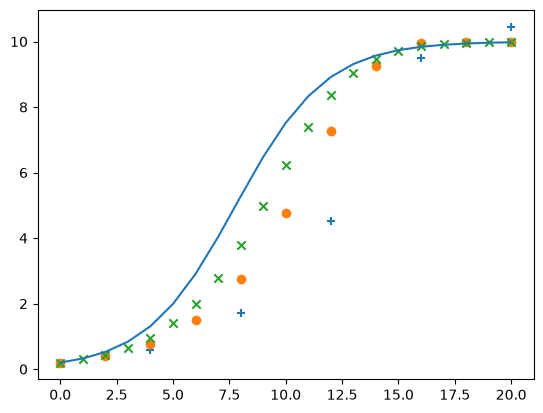

In [5]:
## D
D1 = np.array([(i*20/5,v) for i,v in enumerate(ForwardEuler(0,20,5 ,1/5))])
D2 = np.array([(i*20/10,v) for i,v in enumerate(ForwardEuler(0,20,10,1/5))])
D3 = np.array([(i*20/20,v) for i,v in enumerate(ForwardEuler(0,20,20,1/5))])
R1 = np.array([(i*20/20,y_fn(i*20/20)) for i in range(21)])


plt.scatter(D1[:,0],D1[:,1],marker='+')
plt.scatter(D2[:,0],D2[:,1],marker='o')
plt.scatter(D3[:,0],D3[:,1],marker='x')
plt.plot(R1[:,0],R1[:,1])
plt.show()

In [6]:
## E
def ExplicitMidpoint(t0,tf,N,y0):
    h = (tf-t0)/N
    res = [y0]
    
    tn=t0
    yn=y0
    for _ in range(N):
        k1=Dynamics(tn,yn)
        k2=Dynamics(tn+h/2,yn+h*k1/2)
        yn1=yn+h*k2
        res.append(yn1)
        tn,yn=tn+h,yn1
    return res

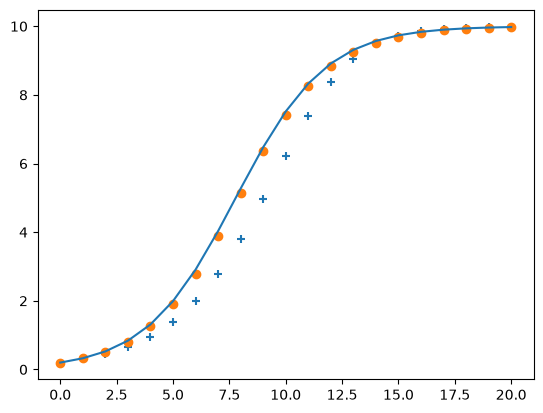

In [7]:
## F
FE = np.array([(i,v) for i,v in enumerate(ForwardEuler(0,20,20,1/5))])
EM = np.array([(i,v) for i,v in enumerate(ExplicitMidpoint(0,20,20,1/5))])
R1 = np.array([(i,y_fn(i)) for i in range(21)])


plt.scatter(FE[:,0],FE[:,1],marker='+')
plt.scatter(EM[:,0],EM[:,1],marker='o')
plt.plot(R1[:,0],R1[:,1])
plt.show()

In [10]:
## G
def NumericalAnalysis(fn):
    t0=0
    tf=10
    y0=1/5
    yf=y_fn(tf)

    prev_err=None
    for i in range(9):
        N=5*2**i
        Y_i = fn(t0,tf,N,y0)
        new_err = abs(Y_i[-1]-yf)
        assert(new_err != 0)
        print(f"{i}\t{new_err}\t{new_err/prev_err if prev_err is not None else "--"}")
        prev_err=new_err
NumericalAnalysis(ForwardEuler)


0	2.7567273621213904	--
1	1.2931963281509038	0.4691056307997566
2	0.5903595550558958	0.4565119326467855
3	0.2790799136467985	0.47272871465657057
4	0.1354597212379396	0.48537968737290216
5	0.06671342971235372	0.492496434384132
6	0.03310362393916222	0.4962062973211558
7	0.016488698396525336	0.4980934542643499
8	0.0082285926041612	0.49904440036911657


Based on values observed the number is converging to 0.5 hence p=1, O(h)

In [ ]:
## H
NumericalAnalysis(ExplicitMidpoint)

0	0.3076025813453853	--
1	0.10000151286599035	0.32509971934762694
2	0.02863430517608201	0.28633871983971043
3	0.007690847727684691	0.2685885926126397
4	0.0019956740131492623	0.2594868711241608
5	0.0005085028522611168	0.254802562397792
6	0.00012835498707008952	0.2524174377770827
7	3.224443238014629e-05	0.2512129299856413
8	8.080697854850882e-06	0.2506075392980517


Based on observed valeus, the number is convering to 0.25, hence p=2, O(h^2)